- BY - Oliver Tschudi Madsen
- GITHUB - https://github.com/OTMadsen/IND320
- Streamlit App - ind320-jv4zs4xscqztj8g52d5r6w.streamlit.app
- Screenrecord Link - https://youtu.be/FHF-4WK4q5U



- I had some quite complicated issues with downloading Spark and making it work, so there are a few AI-generated snippets I used to solve the issues I received. I apologize for this inconvenience. These are placed here at the top of the notebook. 

- Additional AI was also used to correct and sometimes generate some lines of code since I am new relatively new to both Spark and Cassanda. All the code was both examined and tested thoroughly and printed out as they should!

- Also due to some poor planning I think I did some errors on moving the files to GitHub. I may have placed them in the wrong place for now. This will of course be adjusted if there is any errors accessing this. There were some experimenting on pulls here and there, so there may be a bit messy!

In [ ]:
#With help from AI I used the OS on my computer to access files to make sure that Spark worked out. These are the connections that were established. 

import os
import sys

os.environ["JAVA_HOME"] = r"C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot"
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["SPARK_SUBMIT_OPTS"] = "-Dhadoop.home.dir=C:/hadoop"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["SPARK_SUBMIT_OPTS"] = "-Dhadoop.home.dir=C:/hadoop"

os.environ["PATH"] = (
    os.path.join(os.environ["JAVA_HOME"], "bin") + os.pathsep +
    os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep +
    os.environ["PATH"]
)

In [ ]:
#This was the proper connection using both Cassandra and Spark together. 

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_project")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.jars.packages",
            "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

print("Spark Version", spark.version)
print("Connector", spark.sparkContext.getConf().get("spark.jars.packages"))

Spark Version 3.5.1
Connector com.datastax.spark:spark-cassandra-connector_2.12:3.5.1


In [6]:
#This is a shortcut for the env-file which is provided in the project

from dotenv import load_dotenv
import os

load_dotenv(".env")

ENTSOE_API_KEY = os.getenv("ENTSOE_API_KEY")
KEYSPACE = os.getenv("CASSANDRA_KEYSPACE", "IND320_project")
MONGODB_URI = os.getenv("MONGODB_URI")

In [3]:
import requests 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

NVE_BASE_URL = ("https://biapi.nve.no/magasinstatistikk")

def get_nve_data(endpoint):
    url = f"{NVE_BASE_URL}/api/Magasinstatistikk{endpoint}"

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    data = response.json()
    return pd.DataFrame(data)

def get_reservoir_data():
    return get_nve_data("HentOffentligData")

def get_reservoir_data():
    url = f"{NVE_BASE_URL}/api/Magasinstatisstikk/HentOmråder"

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    return response.json()

In [4]:
#Retrieving data here with said dataframes just to see what we are working with 

reservoir_response = requests.get(
    f"{NVE_BASE_URL}/api/Magasinstatistikk/HentOffentligData",
    timeout=60
)
reservoir_response.raise_for_status()
reservoir_df = pd.DataFrame(reservoir_response.json())

print("Number of rows", len(reservoir_df))
print(reservoir_df.head(20))
print(reservoir_df.columns.tolist())
print(reservoir_df.dtypes)

Number of rows 14922
       dato_Id omrType  omrnr  iso_aar  iso_uke  fyllingsgrad  kapasitet_TWh  \
0   1995-09-03      EL      4     1995       35      0.944721      21.079208   
1   2020-11-15      EL      1     2020       46      0.974361       6.003264   
2   2011-08-28      EL      4     2011       34      0.786499      21.079208   
3   1998-07-05      EL      3     1998       27      0.793969       8.920932   
4   2011-03-27      EL      4     2011       12      0.300820      21.079208   
5   2017-11-05      EL      4     2017       44      0.794520      21.079208   
6   2000-11-26      EL      4     2000       47      0.866371      21.079208   
7   2016-09-04      EL      1     2016       35      0.890967       6.003264   
8   2023-08-13      EL      5     2023       32      0.836849      17.390587   
9   2011-09-04      EL      3     2011       35      0.881907       8.920932   
10  1995-03-26      EL      5     1995       12      0.295008      17.390587   
11  2021-04-18     

In [5]:
#Here I added som additional libraries for the time range I will later and the necessary libraries for reading in the provided ENTSOE-key

import os 
from datetime import datetime, timedelta
from dotenv import load_dotenv
from entsoe import EntsoePandasClient

load_dotenv()

ENTSOE_API_KEY = os.getenv("ENTSOE_API_KEY")

client = EntsoePandasClient(api_key=ENTSOE_API_KEY)

In [6]:
"""
Here I define the start and end for which I will be working with
THE ENTSOE-token usually have a one year interval at max. Later in the assignment I tried to run the values for a full year.
This took way to long, so the interval was shortened down to reduce the runtime of the code.  

"""
end = pd.Timestamp.now(tz="UTC").floor("h")
start = end - pd.DateOffset(years=2)

print("Start:", start)
print("End:", end)

Start: 2024-10-20 20:00:00+00:00
End: 2026-10-20 20:00:00+00:00


In [7]:
""""""
#The ENTSO-O test worked, so now we can proceed with Cassandra and storing this
from cassandra.cluster import Cluster

cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect()

rows = session.execute("""
    SELECT keyspace_name
    FROM system_schema.keyspaces

""")

In [ ]:
#Here I created a connection to Cassandra, and linked it up with the local project here in VSCode.

cluster = Cluster(["127.0.0.1"], port = 9042)
session = cluster.connect()

session.set_keyspace("ind320_project")

session.execute("""
    CREATE TABLE IF NOT EXISTS physical_flows (
        connection text,
        "timestamp" timestamp,
        direction text,
        value double,
        PRIMARY KEY ((connection), "timestamp", direction)
    )

""")

print("Connected to ind320_project. Table is ready")

Connected to ind320_project. Table is ready


In [9]:
#Next step is to retrieve the date from ENTSO and store it in Cassandra. Here I also define the time ranges for the plots, as well as defines the data that is going both in and out of Norway and in this case Denmark 
import os
from entsoe import EntsoePandasClient

client = EntsoePandasClient(api_key=os.getenv("ENTSOE_API_KEY"))

start = pd.Timestamp("2025-01-01", tz="Europe/Oslo")
end = pd.Timestamp("2025-02-01", tz="Europe/Oslo")


out_flows = client.query_crossborder_flows(
    country_code_from="NO_2",
    country_code_to="DE_LU",
    start=start,
    end=end
)

in_flows = client.query_crossborder_flows(
    country_code_from="DE_LU",
    country_code_to="NO_2",
    start=start, 
    end=end
)

print("Outgoing")
print(out_flows.head(10))

print("\nIncoming:")
print(in_flows.head(10))



Outgoing
2025-01-01 00:00:00+01:00    0.0
2025-01-01 00:15:00+01:00    0.0
2025-01-01 00:30:00+01:00    0.0
2025-01-01 00:45:00+01:00    0.0
2025-01-01 01:00:00+01:00    0.0
2025-01-01 01:15:00+01:00    0.0
2025-01-01 01:30:00+01:00    0.0
2025-01-01 01:45:00+01:00    0.0
2025-01-01 02:00:00+01:00    0.0
2025-01-01 02:15:00+01:00    0.0
Freq: 15min, dtype: float64

Incoming:
2025-01-01 00:00:00+01:00    1017.46
2025-01-01 00:15:00+01:00    1119.82
2025-01-01 00:30:00+01:00    1120.12
2025-01-01 00:45:00+01:00    1119.89
2025-01-01 01:00:00+01:00    1120.26
2025-01-01 01:15:00+01:00    1120.32
2025-01-01 01:30:00+01:00    1119.66
2025-01-01 01:45:00+01:00    1068.21
2025-01-01 02:00:00+01:00     867.32
2025-01-01 02:15:00+01:00     818.40
Freq: 15min, dtype: float64


In [10]:
#Using Spark we connect to Cassandra as well as checking the version. This was one of the issues I had during this assignment, so I just printed it out to be sure. 

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("IND320_project")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .config("spark.cassandra.connection.port", "9042")
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.1


In [11]:
#Here we display the four columns with Spark which we are verifying later, 

df_out = out_flows.rename("value").reset_index()
df_out.columns = ["timestamp", "value"]
df_out["direction"] = "out"


df_in = in_flows.rename("value").reset_index()
df_in.columns = ["timestamp", "value"]
df_in["direction"] = "in"

df = pd.concat([df_out, df_in], ignore_index=True)

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df["timestamp"] = df["timestamp"].dt.tz_localize(None)
df["value"] = df["value"].astype(float)
df["connection"] = "NO_2 - DE_LU"

spark_df = spark.createDataFrame(df)

spark_df.show(10)

+-------------------+-----+---------+------------+
|          timestamp|value|direction|  connection|
+-------------------+-----+---------+------------+
|2024-12-31 23:00:00|  0.0|      out|NO_2 - DE_LU|
|2024-12-31 23:15:00|  0.0|      out|NO_2 - DE_LU|
|2024-12-31 23:30:00|  0.0|      out|NO_2 - DE_LU|
|2024-12-31 23:45:00|  0.0|      out|NO_2 - DE_LU|
|2025-01-01 00:00:00|  0.0|      out|NO_2 - DE_LU|
|2025-01-01 00:15:00|  0.0|      out|NO_2 - DE_LU|
|2025-01-01 00:30:00|  0.0|      out|NO_2 - DE_LU|
|2025-01-01 00:45:00|  0.0|      out|NO_2 - DE_LU|
|2025-01-01 01:00:00|  0.0|      out|NO_2 - DE_LU|
|2025-01-01 01:15:00|  0.0|      out|NO_2 - DE_LU|
+-------------------+-----+---------+------------+
only showing top 10 rows



In [13]:
#Here I saved the data to Cassandra 
spark_df.write \
.format("org.apache.spark.sql.cassandra") \
.mode("append") \
.options(
    keyspace="ind320_project",
    table="physical_flows"
) \
.save()

print("Sucessfully saved to Cassandra, and now awaits the plotting")


Sucessfully saved to Cassandra, and now awaits the plotting


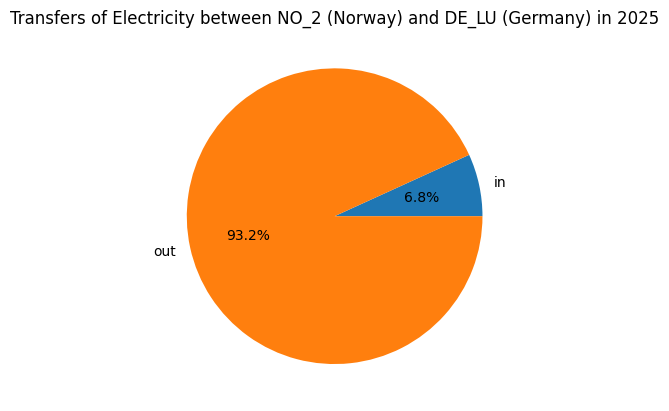

In [14]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F 

el_energy_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320_project", table="physical_flows")
    .load()
    .withColumn("year", F.year("timestamp"))  
)

pie_df_chart = (
    el_energy_df
    .filter(
        (F.col("year") == 2025) &
        (F.col("connection") == "NO_2 - DE_LU")
    )
    .groupBy("direction")
    .agg((F.sum(F.col("value").cast("double"))*0.25).alias("total")) #Now checks intervals every hour instead of every 15 minutes
    .toPandas()
)

if not pie_df_chart.empty:
    plt.pie(
        pie_df_chart["total"],
        labels=pie_df_chart["direction"],
        autopct="%1.1f%%"

    )

    plt.title("Transfers of Electricity between NO_2 (Norway) and DE_LU (Germany) in 2025")
    plt.show()
else:
    print("No data found. Please try again")


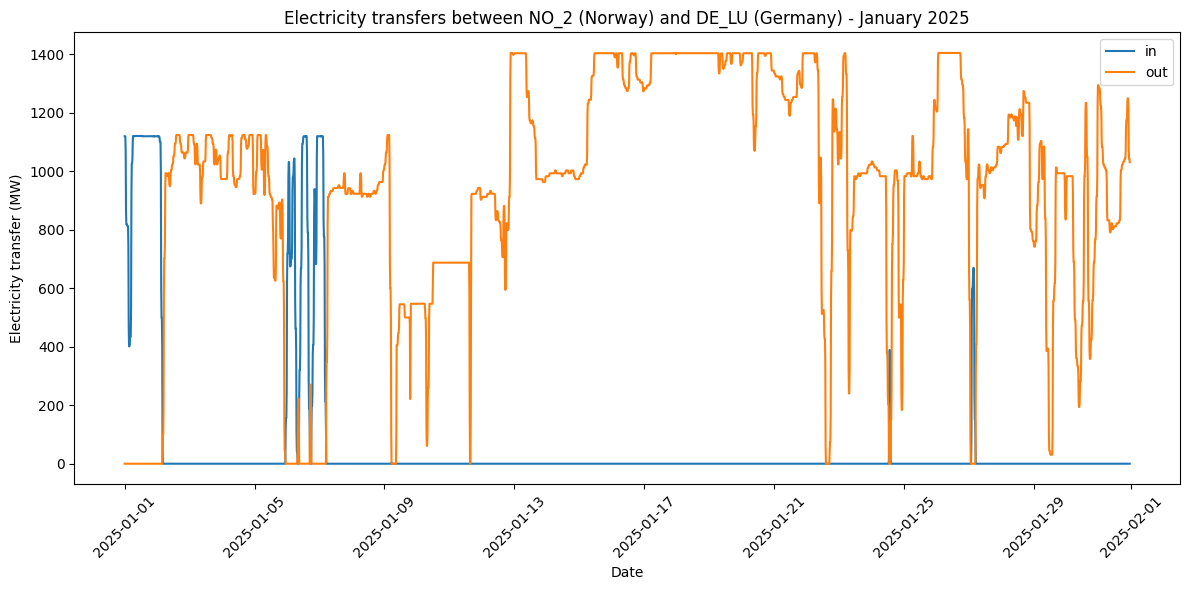

In [15]:
#And now for the lineplot, also between Norway and Germany. 

line_df_chart = (
    el_energy_df
    .filter(
        (F.col("year") == 2025) &
        (F.month("timestamp") == 1) &
        (F.regexp_replace(F.col("connection"), " ", "") == "NO_2-DE_LU")
    )
    .orderBy("timestamp")
    .toPandas()
)

if not line_df_chart.empty:
    plt.figure(figsize=(12, 6))

    for direction, group in line_df_chart.groupby("direction"):
        plt.plot(
            group["timestamp"],
            group["value"],
            label=direction
        )

    plt.xlabel("Date")
    plt.ylabel("Electricity transfer (MW)")
    plt.title("Electricity transfers between NO_2 (Norway) and DE_LU (Germany) - January 2025")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("No data found for Norway - Germany in January 2025.")

In [ ]:
"""
Now that this data has been processed and plotted, the final step is to move the Spark-Extracted data to MongoDB. 

Using some of the libraries from earlier, we are now going to move it. 

"""

import os 
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv(".env")

mongo_uri = os.getenv("MONGODB_URI")

client_mongo = MongoClient(mongo_uri)
client_mongo.admin.command("ping")

print("Connected to Mongo!")



Connected to Mongo!


In [ ]:
#Now we extract the relevant columns using Spark from earlier

mongo_spark_df = el_energy_df.select(
    "timestamp",
    "connection",
    "direction",
    "value",
)

mongo_df = mongo_spark_df.toPandas()

records = mongo_df.to_dict("records")

print(f"Prepared {len(records)} records for MongoDB")


#Here we store the given data in MongoDB

db = client_mongo["ind320_project"]
collection = db["electricity_flows"]

collection.delete_many({}) #This rules out previously imported data to avoid duplicates 

if records:
    collection.insert_many(records)


print(f"Saved{len(records)} to MongoDB")

Prepared 9144 records for MongoDB
Saved9144 to MongoDB


In [ ]:
#Lastly, just to be sure everything is alright, we verify the data in Mongo

print("Documents in MongoDB:", collection.count_documents({}))

for document in collection.find({}, {"_id:0"}).limit(5):
    print(document)

Documents in MongoDB: 9144
{'_id': ObjectId('6ad6836cf195c04bc4936f60')}
{'_id': ObjectId('6ad6836cf195c04bc4936f61')}
{'_id': ObjectId('6ad6836cf195c04bc4936f62')}
{'_id': ObjectId('6ad6836cf195c04bc4936f63')}
{'_id': ObjectId('6ad6836cf195c04bc4936f64')}
